In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
class Source:
    def __init__(self, Y=10000):
        self.Y = Y

    def generate_directions(self, E, batch_size=100):
        # Случайное количество фотонов по распределению Пуассона
        n_photons = np.random.poisson(self.Y * E)

        # Генерация фотонов порциями
        for start in range(0, n_photons, batch_size):

            # Размер текущей порции
            n = min(batch_size, n_photons - start)

            # Случайные сферические координаты
            phi = np.random.uniform(0, 2 * np.pi, n)
            cos_theta = np.random.uniform(-1, 1, n)

            sin_theta = np.sqrt(1 - cos_theta**2)

            # Декартовы координаты единичных векторов
            directions = np.column_stack((
                sin_theta * np.cos(phi),
                sin_theta * np.sin(phi),
                cos_theta
            ))

            yield directions

In [18]:
class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

        self.pm_positions = self.generate_positions()

    def generate_positions(self):
        """Равномерное распределение фотоумножителей по сфере."""
        positions = []
        golden_angle = np.pi * (3 - np.sqrt(5))

        for i in range(self.N):
            z = 1 - 2 * (i + 0.5) / self.N
            theta = golden_angle * i
            rho = np.sqrt(1 - z**2)

            x = self.R * rho * np.cos(theta)
            y = self.R * rho * np.sin(theta)
            z = self.R * z

            positions.append([x, y, z])

        return np.array(positions)

    def is_on_detector(self, point, tol=1e-6):
        return abs(np.linalg.norm(point) - self.R) < tol

    def belongs_to_pm(self, point):
        """Проверяет, попадает ли точка в какой-либо фотоумножитель."""
        point = np.asarray(point)

        if not self.is_on_detector(point):
            return False

        cos_angles = self.pm_positions @ point / self.R**2
        cos_angles = np.clip(cos_angles, -1, 1)

        distances = self.R * np.arccos(cos_angles)

        return np.any(distances <= self.r)

    def find_photomultiplier(self, source, direction):
        """
        Определяет, в какой фотоумножитель попал фотон.
        Возвращает индекс фотоумножителя или None.
        """
        source = np.asarray(source)
        direction = np.asarray(direction)

        # Находим пересечение траектории со сферой
        dot = np.dot(source, direction)

        t = -dot + np.sqrt(
            dot**2 + self.R**2 - np.dot(source, source)
        )

        hit_point = source + t * direction

        # Проверяем расстояния до всех фотоумножителей
        cos_angles = self.pm_positions @ hit_point / self.R**2
        cos_angles = np.clip(cos_angles, -1, 1)

        distances = self.R * np.arccos(cos_angles)

        # Индексы фотоумножителей, на которые попал фотон
        hits = np.where(distances <= self.r)[0]

        if len(hits) == 0:
            return None

        return hits[0]

    def generate_photoelectrons(self, n_photons):
        """Разыгрывает количество фотоэлектронов."""
        return np.random.poisson(self.a * n_photons)

    def simulate_event(self, source, E, source_position):
        source_position = np.asarray(source_position)

        n_hits = 0

        cos_limit = np.cos(self.r / self.R)

        # Последовательно обрабатываем порции фотонов
        for directions in source.generate_directions(E):

            # Пересечение лучей с поверхностью сферы
            dot = directions @ source_position

            t = -dot + np.sqrt(
                dot**2 + self.R**2 - np.dot(source_position, source_position)
            )

            hit_points = source_position + t[:, None] * directions

            # Проверка попадания фотонов на фотокатоды
            cos_angles = (hit_points / self.R) @ (
                self.pm_positions / self.R
            ).T

            hits = np.max(cos_angles, axis=1) >= cos_limit

            # Суммируем попадания из всех порций
            n_hits += np.sum(hits)

        # Генерируем суммарное число фотоэлектронов
        return np.random.poisson(self.a * n_hits)


In [16]:
# Моделирование одного события с возможностью учёта затухания
def simulate_event_with_attenuation(
    detector, source, E, source_position, attenuation_length=None
):
    source_position = np.asarray(source_position, dtype=float)

    n_hits = 0
    cos_limit = np.cos(detector.r / detector.R)

    # Обрабатываем фотоны порциями
    for directions in source.generate_directions(E):

        # Расстояние от источника до поверхности сферы
        dot = directions @ source_position

        t = -dot + np.sqrt(
            dot**2
            + detector.R**2
            - np.dot(source_position, source_position)
        )

        # Точки пересечения лучей с поверхностью сферы
        hit_points = source_position + t[:, None] * directions

        # Проверяем попадание фотонов на фотокатоды
        cos_angles = (hit_points / detector.R) @ (
            detector.pm_positions / detector.R
        ).T

        hits = np.max(cos_angles, axis=1) >= cos_limit

        # Учитываем экспоненциальное затухание
        if attenuation_length is not None:
            survival_probability = np.exp(-t / attenuation_length)

            survived = (
                np.random.random(len(directions)) < survival_probability
            )

            hits &= survived

        n_hits += np.sum(hits)

    # Число зарегистрированных фотоэлектронов
    return np.random.poisson(detector.a * n_hits)


# Моделирование нескольких событий
def run_simulations(
    detector, source, E, position,
    n_events=1000, attenuation_length=None
):
    results = []

    for _ in range(n_events):
        Q = simulate_event_with_attenuation(
            detector,
            source,
            E,
            position,
            attenuation_length
        )
        results.append(Q)

    return np.array(results)

In [ ]:
# Создаем экземпляры классов
detector = Detector(R=2.0, N=40, r=0.1, a=0.5)
source = Source(Y=10000)

# Параметры моделирования
E = 1.0
attenuation_length = 8.0
n_events = 1000

# Положения источника вдоль вертикальной оси
z_positions = np.linspace(
    -0.75 * detector.R,
     0.75 * detector.R,
     7
)

# Результаты моделирования
results_no_attenuation = {}
results_with_attenuation = {}

for z in z_positions:
    position = np.array([0.0, 0.0, z])

    # Без затухания
    results_no_attenuation[z] = run_simulations(
        detector,
        source,
        E,
        position,
        n_events=n_events
    )

    # С затуханием
    results_with_attenuation[z] = run_simulations(
        detector,
        source,
        E,
        position,
        n_events=n_events,
        attenuation_length=attenuation_length
    )


# Вычисление средних значений, стандартных отклонений и ошибок среднего
means_no = []
means_att = []

stds_no = []
stds_att = []

errors_no = []
errors_att = []

for z in z_positions:
    res_no = results_no_attenuation[z]
    res_att = results_with_attenuation[z]

    mean_no = np.mean(res_no)
    mean_att = np.mean(res_att)

    std_no = np.std(res_no, ddof=1)
    std_att = np.std(res_att, ddof=1)

    means_no.append(mean_no)
    means_att.append(mean_att)

    stds_no.append(std_no)
    stds_att.append(std_att)

    errors_no.append(std_no / np.sqrt(n_events))
    errors_att.append(std_att / np.sqrt(n_events))

    change = (mean_att / mean_no - 1) * 100

    print(
        f"z = {z:5.2f} м | "
        f"Без затухания: {mean_no:.2f} ± {errors_no[-1]:.2f} | "
        f"С затуханием: {mean_att:.2f} ± {errors_att[-1]:.2f} | "
        f"Изменение: {change:.2f} %"
    )

z = -1.50 м | Без затухания: 122.77 ± 0.44 | С затуханием: 100.98 ± 0.39 | Изменение: -17.75 %
z = -1.00 м | Без затухания: 125.73 ± 0.45 | С затуханием: 99.79 ± 0.39 | Изменение: -20.63 %
z = -0.50 м | Без затухания: 124.82 ± 0.41 | С затуханием: 98.08 ± 0.39 | Изменение: -21.42 %
z =  0.00 м | Без затухания: 125.01 ± 0.43 | С затуханием: 97.72 ± 0.39 | Изменение: -21.83 %
z =  0.50 м | Без затухания: 124.45 ± 0.44 | С затуханием: 98.37 ± 0.38 | Изменение: -20.96 %
z =  1.00 м | Без затухания: 124.79 ± 0.42 | С затуханием: 99.21 ± 0.39 | Изменение: -20.50 %
z =  1.50 м | Без затухания: 121.93 ± 0.42 | С затуханием: 100.86 ± 0.39 | Изменение: -17.28 %


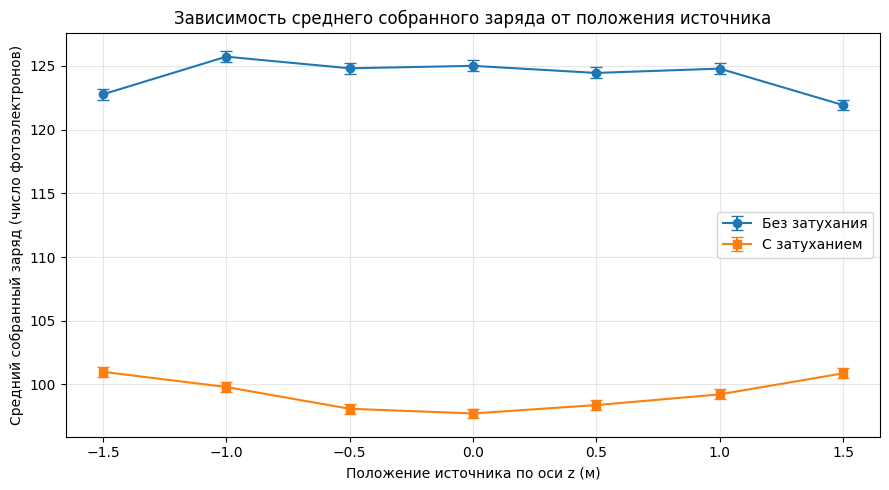

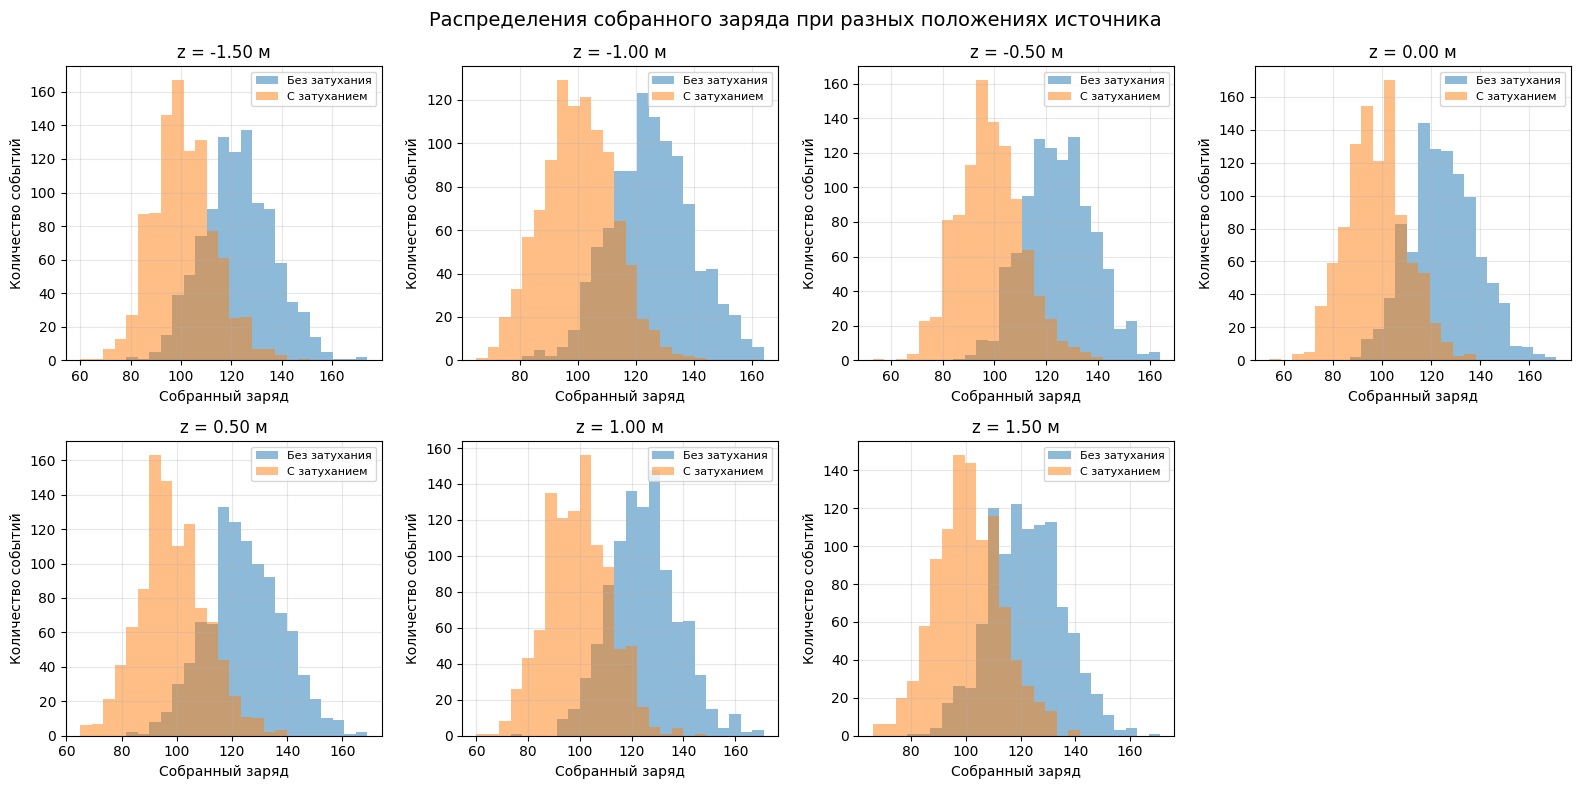

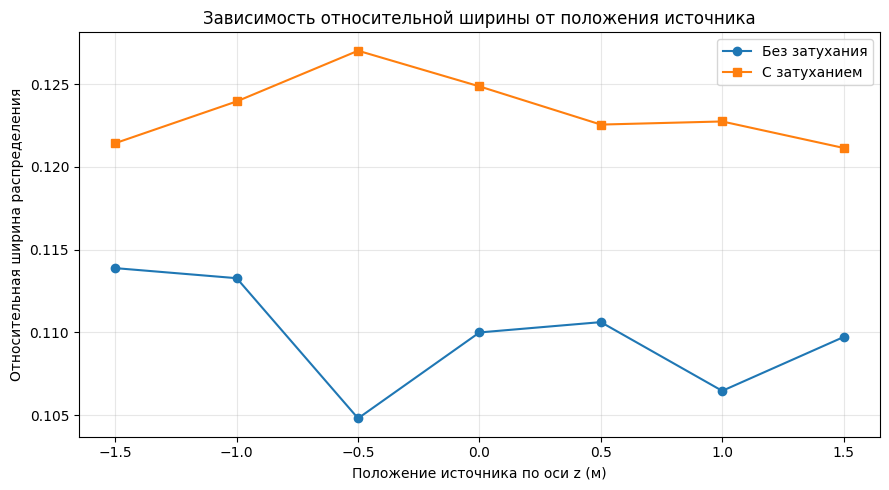

In [19]:
# График зависимости среднего собранного заряда от положения источника
plt.figure(figsize=(9, 5))

plt.errorbar(
    z_positions,
    means_no,
    yerr=errors_no,
    fmt='o-',
    capsize=4,
    label='Без затухания'
)

plt.errorbar(
    z_positions,
    means_att,
    yerr=errors_att,
    fmt='s-',
    capsize=4,
    label='С затуханием'
)

plt.xlabel('Положение источника по оси z (м)')
plt.ylabel('Средний собранный заряд (число фотоэлектронов)')
plt.title('Зависимость среднего собранного заряда от положения источника')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Гистограммы распределений для разных положений источника
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, z in zip(axes.flat, z_positions):

    res_no = results_no_attenuation[z]
    res_att = results_with_attenuation[z]

    low = min(res_no.min(), res_att.min())
    high = max(res_no.max(), res_att.max())

    bins = np.linspace(low, high + 1, 26)

    ax.hist(
        res_no,
        bins=bins,
        alpha=0.5,
        label='Без затухания'
    )

    ax.hist(
        res_att,
        bins=bins,
        alpha=0.5,
        label='С затуханием'
    )

    ax.set_xlabel('Собранный заряд')
    ax.set_ylabel('Количество событий')
    ax.set_title(f'z = {z:.2f} м')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

# Отключаем последнюю пустую область
axes.flat[-1].axis('off')

fig.suptitle(
    'Распределения собранного заряда при разных положениях источника',
    fontsize=14
)

plt.tight_layout()
plt.show()


# Сравнение относительной ширины распределений
relative_width_no = np.array(stds_no) / np.array(means_no)
relative_width_att = np.array(stds_att) / np.array(means_att)

plt.figure(figsize=(9, 5))

plt.plot(
    z_positions,
    relative_width_no,
    'o-',
    label='Без затухания'
)

plt.plot(
    z_positions,
    relative_width_att,
    's-',
    label='С затуханием'
)

plt.xlabel('Положение источника по оси z (м)')
plt.ylabel('Относительная ширина распределения')
plt.title('Зависимость относительной ширины от положения источника')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()